# Small U-Net for Binary Segmentation (Oxford-IIIT Pet)

I've used pretrained segmentation models, but never written the U-Net skip connections myself. This notebook does that on real photos: segment the pet from the background in the Oxford-IIIT Pet dataset (Parkhi et al., 2012, CC BY-SA 4.0), which ships a hand-drawn trimap for every image (pet, background, and an uncertain border band). I treat pet + border as foreground.

Images come from the `timm/oxford-iiit-pet` parquet on Hugging Face (first 10 row groups, 1,000 photos), and the trimaps from the official `annotations.tar.gz` on the Oxford VGG site (19MB), matched by image name. Everything is resized to 64x64 to keep CPU training short.

Architecture target: tiny U-Net (3 encoder blocks, 3 decoder blocks, skip connections, sigmoid head). 800 training and 200 validation images.

In [1]:
import io, tarfile, urllib.request
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from huggingface_hub import HfFileSystem
from PIL import Image

torch.set_num_threads(2)
torch.manual_seed(2); np.random.seed(2)
device = "cpu"
print("device:", device)

device: cpu


## Real dataset: pet photo + trimap mask

images: (1000, 3, 64, 64)  masks: (1000, 1, 64, 64)  foreground share: 0.414


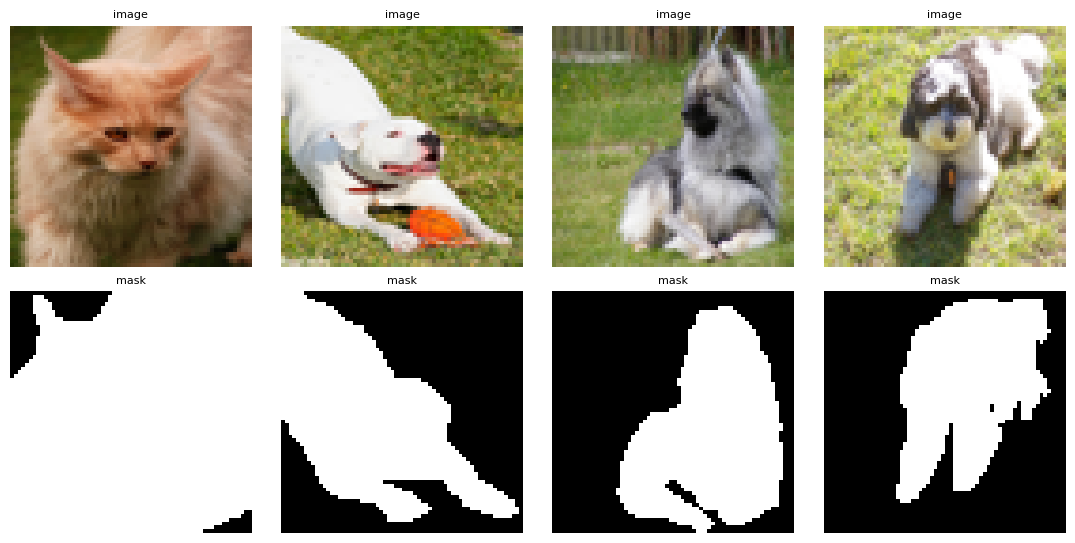

In [2]:
SIZE = 64
DATA = Path("../../data/oxford_pets")
ANN = DATA / "annotations.tar.gz"
if not ANN.exists():
    DATA.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve("https://thor.robots.ox.ac.uk/datasets/pets/annotations.tar.gz", ANN)

# 1,000 photos from the HF parquet (first 10 row groups)
fs = HfFileSystem()
pf = pq.ParquetFile(fs.open("datasets/timm/oxford-iiit-pet/data/train-00000-of-00001.parquet"))
rows = [r for g in range(10) for r in pf.read_row_group(g, columns=["image", "image_id"]).to_pylist()]
wanted = {r["image_id"] for r in rows}

# matching trimaps: 1 = pet, 2 = background, 3 = border band
trimaps = {}
with tarfile.open(ANN) as tf:
    for m in tf.getmembers():
        name = Path(m.name).stem
        if m.name.startswith("annotations/trimaps/") and m.name.endswith(".png") and name in wanted:
            tri = Image.open(io.BytesIO(tf.extractfile(m).read())).resize((SIZE, SIZE), Image.NEAREST)
            trimaps[name] = (np.asarray(tri) != 2).astype(np.float32)   # pet or border -> 1

imgs, masks = [], []
for r in rows:
    if r["image_id"] in trimaps:
        im = Image.open(io.BytesIO(r["image"]["bytes"])).convert("RGB").resize((SIZE, SIZE))
        imgs.append(np.asarray(im, dtype=np.float32).transpose(2, 0, 1) / 255.0)
        masks.append(trimaps[r["image_id"]][None])
imgs, masks = np.stack(imgs), np.stack(masks)
print("images:", imgs.shape, " masks:", masks.shape, " foreground share:", masks.mean().round(3))

class PetsDS(Dataset):
    def __init__(self, x, m):
        self.x, self.m = torch.tensor(x), torch.tensor(m)
    def __len__(self): return len(self.x)
    def __getitem__(self, i): return self.x[i], self.m[i]

train_ds = PetsDS(imgs[:800], masks[:800])
val_ds = PetsDS(imgs[800:], masks[800:])
train_dl = DataLoader(train_ds, batch_size=16, shuffle=True)
val_dl   = DataLoader(val_ds, batch_size=16)

# eyeball: image, mask
fig, axes = plt.subplots(2, 4, figsize=(11, 5.5))
for j in range(4):
    x, m = train_ds[j]
    axes[0, j].imshow(x.permute(1, 2, 0).numpy().clip(0, 1))
    axes[0, j].set_title("image", fontsize=8); axes[0, j].axis("off")
    axes[1, j].imshow(m[0].numpy(), cmap="gray")
    axes[1, j].set_title("mask",  fontsize=8); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

## The U-Net

A U-Net is just: encoder (downsamples), decoder (upsamples), and **skip connections** that concat encoder features into the matching-resolution decoder block. The skips are the whole point — they let the decoder use high-resolution spatial information from the encoder when it's putting boundaries back together.

Small version: 3 stages, channels 16 → 32 → 64. Each "block" is two 3x3 convs with ReLU.

In [3]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.ReLU(inplace=True),
    )

class TinyUNet(nn.Module):
    def __init__(self):
        super().__init__()
        # encoder
        self.enc1 = conv_block(3, 16)
        self.enc2 = conv_block(16, 32)
        self.enc3 = conv_block(32, 64)
        self.pool = nn.MaxPool2d(2)
        # decoder (upsample then concat skip)
        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec2 = conv_block(64, 32)   # 32 (from up) + 32 (skip)
        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec1 = conv_block(32, 16)   # 16 + 16
        # head
        self.out = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)               # 64x64x16
        e2 = self.enc2(self.pool(e1))   # 32x32x32
        e3 = self.enc3(self.pool(e2))   # 16x16x64
        d2 = self.up2(e3)               # 32x32x32
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)               # 64x64x16
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return self.out(d1)             # logits, 64x64x1

model = TinyUNet().to(device)
print(sum(p.numel() for p in model.parameters()), "params")

117041 params


## Train. Dice + BCE loss.

In [4]:
def dice_loss(logits, target, eps=1e-6):
    pred = torch.sigmoid(logits)
    inter = (pred * target).sum(dim=(1, 2, 3))
    union = pred.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return 1 - ((2 * inter + eps) / (union + eps)).mean()

bce = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 6   # about a minute per epoch on CPU at this size
for ep in range(EPOCHS):
    model.train(); total, n = 0, 0
    for x, m in train_dl:
        x, m = x.to(device), m.to(device)
        opt.zero_grad()
        logits = model(x)
        loss = bce(logits, m) + dice_loss(logits, m)
        loss.backward(); opt.step()
        total += loss.item() * x.size(0); n += x.size(0)
    print(f"ep {ep+1}  train_loss={total/n:.3f}")

ep 1  train_loss=1.196


ep 2  train_loss=1.011


ep 3  train_loss=0.936


ep 4  train_loss=0.902


ep 5  train_loss=0.898


ep 6  train_loss=0.863


## Qualitative eval — show predicted masks

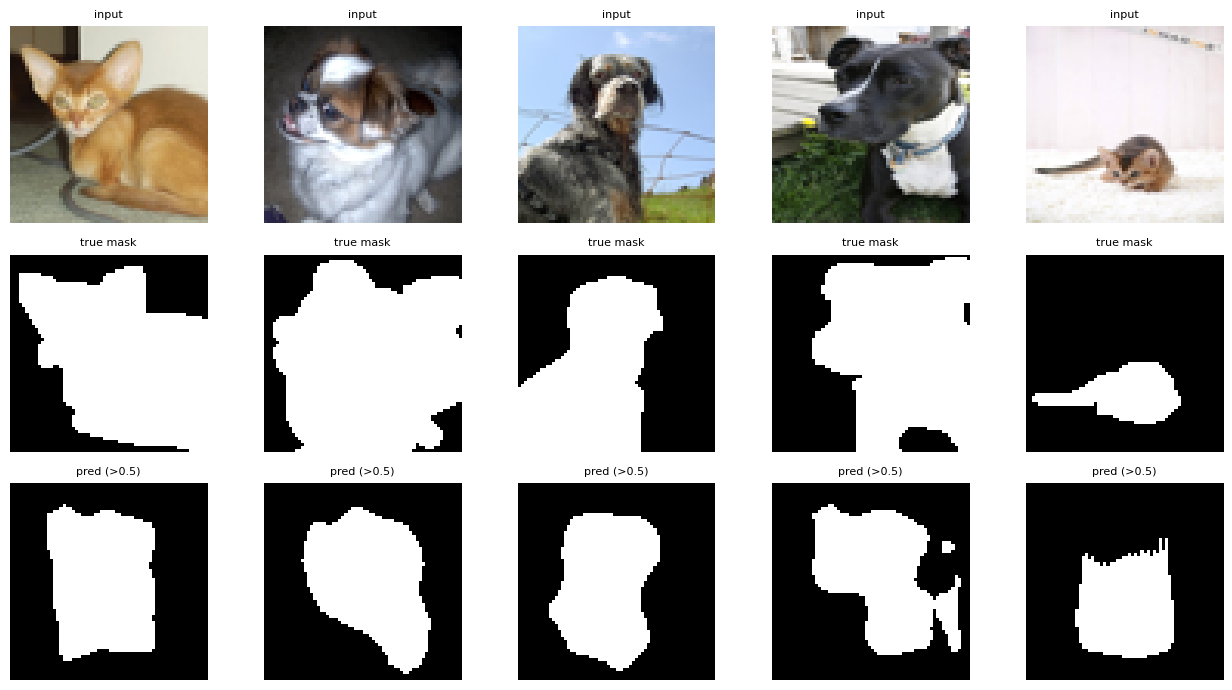

mean IoU on val: 0.585
baseline IoU (everything = pet): 0.415


In [5]:
model.eval()
xb, mb = next(iter(val_dl))
with torch.no_grad():
    pred = torch.sigmoid(model(xb.to(device))).cpu().numpy()

fig, axes = plt.subplots(3, 5, figsize=(13, 7))
for j in range(5):
    axes[0, j].imshow(xb[j].permute(1, 2, 0).numpy().clip(0, 1)); axes[0, j].set_title("input", fontsize=8); axes[0, j].axis("off")
    axes[1, j].imshow(mb[j, 0].numpy(), cmap="gray"); axes[1, j].set_title("true mask", fontsize=8); axes[1, j].axis("off")
    axes[2, j].imshow(pred[j, 0] > 0.5, cmap="gray"); axes[2, j].set_title("pred (>0.5)", fontsize=8); axes[2, j].axis("off")
plt.tight_layout(); plt.show()

# IoU over the val set as a single summary number
def iou(pred, target, thresh=0.5):
    p = (pred > thresh).float()
    inter = (p * target).sum(dim=(1, 2, 3))
    union = ((p + target) > 0).float().sum(dim=(1, 2, 3))
    return ((inter + 1e-6) / (union + 1e-6)).mean().item()

ious = []
with torch.no_grad():
    for x, m in val_dl:
        x, m = x.to(device), m.to(device)
        ious.append(iou(torch.sigmoid(model(x)), m))
print(f"mean IoU on val: {np.mean(ious):.3f}")
# trivial baseline: call every pixel "pet"
print(f"baseline IoU (everything = pet): {np.mean([iou(torch.ones_like(m), m) for _, m in val_dl]):.3f}")


## Notes

Six epochs on 800 real photos gets mean IoU 0.585 on the 200 validation images. For scale, calling every pixel "pet" scores 0.415, because pets fill about 41% of these frames. So the U-Net has learned something real, but not much yet.

The qualitative panel is the more honest read. The predicted masks are mostly soft, centered blobs: the model has learned "the pet is usually in the middle and big" plus a bit of color contrast, and it gets the rough extent right on the easy shots. It misses ears, legs and tails, and on the kitten lying at the bottom of the frame it puts a blob in the center instead of on the cat. Training loss was still going down (0.86 at the end), so more epochs and augmentation would help, but at 64x64 with a 117K-parameter network from scratch, a center prior is the easiest thing to learn.

What writing this taught me beyond the API:
- The skip connections are the whole point. They are what lets the decoder recover boundaries from high-resolution encoder features, and they're also what this model isn't using well yet: its edges are much smoother than the true masks.
- ConvTranspose2d with stride=2 doubles spatial dimensions but can introduce checkerboard artifacts at high learning rates. With lr=1e-3 it's fine.
- Dice loss alone is unstable when masks are very small (gradients vanish on empty masks). BCE + Dice is the standard combo for a reason.

For a better result on this task I'd swap the encoder for a pretrained ResNet-34, train at 128x128 or larger with flips and crops, and use all 7,349 images. The rest of this architecture stays.